# 20 Netzvergleich und Wintervergleich

## Worum es in diesem Notebook geht

**Zwei Teile, zwei Fragen**

| | Teil A: Netzvergleich | Teil B: Wintervergleich |
|---|---|---|
| **Frage** | Welche Stationen laufen schlecht? | Hat die Begehung etwas gebracht? |
| **Wer** | alle 93 HAST, egal ob begangen oder nicht | nur begangene Stationen + Kontrollgruppe ohne Begehung |
| **Vergleich** | Station gegen alle anderen im selben Kernwinter | dieselbe Station: Kernwinter davor gegen Kernwinter danach |
| **Wofür** | wo als Nächstes hingehen --> geht in die Priorität ein | Erfolgskontrolle --> nur Info in der Statuszeile |

**Kernwinter**
- nur Dezember bis Februar, nur Betriebsstunden
- dann heizen alle Stationen --> Vergleich fair
- 7 Tage vor und nach einer Begehung fallen raus --> Eingriff verfälscht den Normalbetrieb nicht

**Teil A**
- je Station und Winter 5 Kennzahlen aus der Kennlinie (Wasser über Leistung)
- jede Kennzahl gegen die typische Station des Winters (Median, ohne BHKW) --> z-Wert, positiv = schlechter
- Score = Mittel der z-Werte
- auffällig = mind. 2 Kennzahlen im schlechtesten Zehntel, chronisch = in mind. 2 Wintern auffällig
- wichtig für nie begangene Stationen: 4 chronisch auffällige wurden nie besucht

**Teil B**
- Kontrollgruppe = Stationen ohne Begehung im selben Zeitraum
- zwischen zwei Wintern ändert sich bei allen etwas (Wetter, Vorlauf) --> Wirkung = Änderung begangen minus Änderung Kontrollgruppe
- Stationen mit Begehung ohne Datum nicht in der Kontrollgruppe
- ersetzt den alten Vorher/Nachher-Vergleich (NB 03/08), der Spätsommer mit Herbst verglichen hat

**Beispielstation 68956351**
- Ventil jahrelang offen, repariert am 09.09.2024
- Teil A: Rang 1 in 22/23 und 23/24 --> chronisch auffällig
- Teil B: Wasser im Kernwinter 567 --> 103 l/h, Rang 1 --> 40


In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import befundcodes as bc
from src import kennlinien_monitor as km
from src import load_begehungen as lb
from src import load_data as ld
from src import netzvergleich as nv
from src import stationsbilder as sb
from src import ternaer as tn
from src import weather

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

METER_DIR = ROOT / "data" / "processed" / "real_meters"
ZUORDNUNG_PATH = ROOT / "data" / "raw" / "Zuordnung.xlsx"
BEISPIEL = 68956351

t0 = time.time()
serien = tn.lade_serien(METER_DIR)
termine = {int(k): list(v) for k, v in lb.begehung_dates_by_meter().items()}
#Begehungen ohne Datum: begangen, aber zeitlich nicht zuzuordnen (wie NB 16).
#Sie fehlen in der Kontrollgruppe und zählen im Profil als begangen.
beg_alle = lb.begehungen_mit_zaehler()
datiert = {m for m, d in termine.items() if d}
ohne_datum = set(beg_alle["meter"].dropna().astype(int)) - datiert

nodes = ld.load_logical_nodes()
aw_tab = pd.DataFrame({
    "meter": pd.to_numeric(nodes["Zählernummer"], errors="coerce"),
    "kw": pd.to_numeric(nodes["Anschlusswert"], errors="coerce")}).dropna()
anschlusswerte = aw_tab.groupby(aw_tab["meter"].astype(int))["kw"].max().to_dict()

vpin = pd.concat([pd.read_excel(ZUORDNUNG_PATH, sheet_name=s, dtype={"V-PIN": str})
                  [["Zählernummer", "V-PIN"]] for s in ("2024", "2025")])
vpin["Zählernummer"] = pd.to_numeric(vpin["Zählernummer"], errors="coerce")
bhkw = set(vpin.loc[vpin["V-PIN"] == "BHKW", "Zählernummer"].dropna().astype(int))

#Punkttabellen einmal rechnen, Netz- und Wintervergleich nutzen dieselben
punkte = {int(m): sb.punkttabelle(df, int(m), "stunde") for m, df in serien.items()}
print(f"{len(serien)} Zählerreihen, {len(datiert)} Zähler mit datierter Begehung, "
      f"{len(ohne_datum)} mit Begehung ohne Datum, "
      f"{len(anschlusswerte)} mit Anschlusswert, BHKW: {sorted(bhkw)}, "
      f"{time.time() - t0:.0f} s")

/Users/seb/miniconda3/envs/projektseminar/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)
/Users/seb/miniconda3/envs/projektseminar/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


93 Zählerreihen, 56 Zähler mit datierter Begehung, 6 mit Begehung ohne Datum, 99 mit Anschlusswert, BHKW: [86792512], 14 s


## A1 · Kennzahlen je Station und Kernwinter

**Was gerechnet wird**
- für jede Station und jeden Kernwinter (Dez–Feb), egal ob begangen oder nicht
- Kennlinie = Gerade durch log(Volumenstrom) über log(Leistung) --> folgt das Wasser dem Bedarf?
- daraus 5 Kennzahlen:
  - **Spreizung bei Medianleistung**: wie stark die Station bei typischer Last abkühlt, klein = schlecht
  - **Steigung**: gesund ≈ 0,9, offenes Ventil ≈ 0 (Wasser fließt immer gleich), klein = schlecht
  - **Streuung um die Kennlinie**: wie unruhig die Station regelt, groß = schlecht
  - **Anteil Stunden mit Rücklauf > 50 °C**: groß = schlecht
  - **Wasser je kW Anschlusswert**: viel Wasser für die Hausgröße, groß = schlecht

**Welche Stunden zählen**
- nur Betriebsstunden: Leistung, Volumenstrom und Spreizung > 0
- ±7 Tage um eine Begehung raus: Eingriff vor Ort ist kein Normalbetrieb
  --> Puffer symmetrisch aus NB 08/12 ("Umbauphase"), Tage davor nur Vorsicht wegen unsicherem Datum, nicht aus den Daten belegt
  --> betrifft heute nur 2 Stationen in 24/25: 72135443 (Begehung 02.12.2024), 68956339 (Begehung 25.11.2024, Puffer bis 02.12.)
  --> alle anderen Begehungen liegen außerhalb Dez–Feb, bleibt drin für künftige Begehungen im Winter
- mind. 300 Betriebsstunden im ganzen Kernwinter (~2.160 h), nicht pro Monat --> ~14 % des Winters
  --> darunter ist die Kennlinie zu wackelig für einen Vergleich

**Ergebnis**
- Stationen je Winter: 22/23 41, 23/24 86, 24/25 84, 25/26 4
- 21/22 fällt ganz raus: nur Tageswerte (1 Wert pro Tag, max. ~90 je Winter) --> nie 300 h
- 22/23 klein: viele Stationen bis Ende 2022 noch in der Tageswert-Phase
- 25/26 nur 4 Stationen (ODS-Nachlieferung) --> später kein Netzwert, dafür mind. 20 Stationen nötig
- `tabelle` = 1 Zeile je Station und Winter mit den 5 Kennzahlen --> wird in A2 mit dem Netz verglichen


In [2]:
tabelle, ausschluss = nv.winterkennzahlen(punkte, anschlusswerte, termine)
print("Stationen je Winter:")
display(tabelle.groupby("winter").size().to_frame("Stationen"))
print("Ausschlüsse:")
display(ausschluss.groupby(["winter", "grund"]).size().to_frame("Anzahl"))

Stationen je Winter:


,Stationen
winter,
22/23,41
23/24,86
24/25,84
25/26,4


Ausschlüsse:


,,Anzahl
winter,grund,
,keine_daten,1
21/22,zu_wenig_stunden,43
24/25,zu_wenig_stunden,2


## A2 Netzbezug, Redundanz und Score

**A2 · Zelle 1 · Vergleich mit dem Netz, Score, auffällig**

**Was in die Rechnung eingeht**
- Kennzahlen = Features: 1 Zeile je Station und Winter, 5 Spalten
- kein Training, keine Labels --> jede Kennzahl wird nur mit den anderen Stationen desselben Winters verglichen
- Datenmenge: alle Betriebsstunden des Kernwinters, Median ~1.700–2.000 h je Station und Winter
  --> 377.385 Stundenwerte werden zu 215 Zeilen × 5 Zahlen

**z-Wert je Kennzahl**
- z = (Wert − Median des Winters) / (1,4826 × MAD)
- MAD = Median der Abstände zum Median, × 1,4826 --> bei Normalverteilung ≈ Standardabweichung
  --> robust: ein Ausreißer bläht den Maßstab nicht auf und versteckt sich nicht selbst
  --> Beispiel 10, 12, 13, 14, 70: Standardabweichung 25,9 --> z(70) = 1,8; mit MAD 1,48 --> z(70) = 38,5
  --> MAD = 0 (z. B. viele Stationen mit RL-Anteil 0) --> ersatzweise Standardabweichung
- Vorzeichen gedreht --> positiv = immer schlechter, z = 2 heißt 2 übliche Abstände schlechter als die typische Station
- Maßstab = alle Stationen desselben Winters ohne BHKW, mind. 20 --> 25/26 (4 Stationen) bekommt keine z-Werte (`zu_klein`)

**Redundanz (Ausgabe `rho`)**
- rho = Spearman-Rangkorrelation zwischen Wasser je kW und Spreizung (−1 bis +1, 0 = kein Zusammenhang)
  --> vergleicht nur die Reihenfolge der Stationen, robust gegen Ausreißer
- negativ (−0,69 bis −0,78), weil mehr Wasser bei gleicher Leistung = weniger Abkühlung
- Grenze |rho| > 0,9 nicht erreicht --> beide bleiben im Score, sonst würde derselbe Befund doppelt zählen
- n = Stationen mit beiden Werten, 25/26 zu wenige (mind. 5) --> NaN

**Score und auffällig**
- Score = Mittel der 5 z-Werte, Rang 1 = schlechteste Station des Winters
- Kennzahl schlecht = schlechtestes Zehntel des Winters und z > 0
- auffällig = mind. 2 von 5 Kennzahlen schlecht --> 22/23: 6, 23/24: 9, 24/25: 12

**Grenze der Kennzahl Streuung**
- Stundenwerte sind Momentaufnahmen, keine Stundenmittel (Check D2)
  --> schnelles Takten wird einmal pro Stunde zufällig erwischt und erscheint nur als Streuung
- Streuung hoch = Hinweis auf unruhige Regelung, aber nicht von Warmwasser-Spitzen oder Messrauschen zu trennen
- echte Regelhysterese braucht Minutenwerte und das Stellsignal des Reglers --> mit Stundendaten nicht nachweisbar


In [3]:
bezogen = nv.netzbezug(tabelle, referenz_ausschluss=tuple(bhkw) or nv.REFERENZ_AUSSCHLUSS)
kz, rho = nv.score_kennzahlen(bezogen)
display(rho.round(3))
print("Kennzahlen im Score:", list(kz))
markiert = nv.markiere(bezogen, kz)
print(markiert.groupby("winter").agg(stationen=("meter", "size"),
                                     bezug=("bezug", "first"),
                                     auffaellig=("auffaellig", "sum")))

,winter,rho,n
0,22/23,-0.776,38
1,23/24,-0.685,82
2,24/25,-0.740,80
3,25/26,NaN,4


Kennzahlen im Score: ['spreizung_ref_k', 'steigung', 'residuum_sd', 'rl_ueber_50_anteil', 'flow_spez_lh_kw']
        stationen     bezug  auffaellig
winter                                 
22/23          41      netz           6
23/24          86      netz           9
24/25          84      netz          12
25/26           4  zu_klein           0


In [4]:
z_spalten = [f"z_{k}" for k in kz]
for w in ("23/24", "24/25"):
    top = (markiert[markiert["winter"] == w].sort_values("rang")
           [["meter", "rang", "score", "n_kennzahlen", "n_schlecht", "auffaellig", "in_referenz"] + z_spalten]
           .head(10))
    print(f"Schlechteste zehn im Winter {w}:")
    display(top.round(2))

Schlechteste zehn im Winter 23/24:


,meter,rang,score,n_kennzahlen,n_schlecht,auffaellig,in_referenz,z_spreizung_ref_k,z_steigung,z_residuum_sd,z_rl_ueber_50_anteil,z_flow_spez_lh_kw
52,68956351,1.0,3.36,5,4,True,True,2.92,3.64,0.47,1.58,8.19
83,72167777,2.0,2.59,5,4,True,True,2.70,3.59,-1.19,1.61,6.26
85,72167782,3.0,2.51,5,4,True,True,2.60,3.06,-0.66,1.53,6.02
65,68956372,4.0,2.45,5,4,True,True,2.74,3.36,-1.24,1.50,5.89
79,72135480,5.0,2.14,5,3,True,True,2.87,3.57,-0.49,1.62,3.12
112,80912182,6.0,2.04,5,4,True,True,2.38,3.30,-0.22,1.50,3.27
75,72135453,7.0,1.96,5,3,True,True,2.02,1.46,-0.39,1.59,5.09
73,72135442,8.0,1.92,5,1,False,True,1.48,1.48,5.02,0.79,0.81
89,72167793,9.0,1.54,5,2,True,True,1.80,3.21,0.81,1.23,0.65
56,68956356,10.0,1.48,5,1,False,True,1.41,-0.68,3.44,1.03,2.22


Schlechteste zehn im Winter 24/25:


,meter,rang,score,n_kennzahlen,n_schlecht,auffaellig,in_referenz,z_spreizung_ref_k,z_steigung,z_residuum_sd,z_rl_ueber_50_anteil,z_flow_spez_lh_kw
191,80912182,1.0,2.05,5,4,True,True,2.30,3.50,-0.06,1.91,2.57
184,80912173,2.0,2.04,5,4,True,True,2.11,3.51,-0.01,1.84,2.72
155,72135442,3.0,1.94,5,2,True,True,1.32,1.46,2.98,1.16,2.76
170,72167793,4.0,1.87,5,3,True,True,2.41,3.65,-0.37,1.93,1.73
131,68956344,5.0,1.83,5,1,False,True,1.54,0.50,4.26,0.99,1.88
156,72135453,6.0,1.75,5,3,True,True,1.82,1.65,-0.22,1.93,3.57
207,80956410,7.0,1.74,5,3,True,True,1.88,-1.62,2.86,1.57,4.01
160,72135480,8.0,1.52,5,3,True,True,2.18,1.93,-0.21,1.96,1.72
139,68956356,9.0,1.48,5,1,False,True,1.49,2.02,0.80,1.78,1.31
149,68956373,10.0,1.46,5,3,True,True,1.61,-0.80,2.71,1.60,2.20


**A2 · Zelle 2 · Top 10 in 23/24 und 24/25**

**So entsteht der Score (Beispiel 68956351, Winter 23/24)**
1. Kennzahl der Station mit der typischen Station des Winters vergleichen
   z = (Wert − Median) / (1,4826 × MAD), Vorzeichen so, dass positiv = schlechter

   | Kennzahl | Station | Median Netz | Streuung (1,4826 × MAD) | z |
   |---|---|---|---|---|
   | Spreizung [K] | 3,35 | 25,69 | 7,65 | +2,92 (kleiner = schlechter, Vorzeichen gedreht) |
   | Steigung | −0,11 | 0,90 | 0,28 | +3,64 (kleiner = schlechter) |
   | Streuung | 0,28 | 0,23 | – | +0,47 |
   | Anteil RL > 50 °C | 0,99 | 0,35 | – | +1,58 |
   | Wasser je kW [l/h/kW] | 70,9 | 13,6 | 7,0 | +8,19 |

2. Score = Mittel der z-Werte --> (2,92 + 3,64 + 0,47 + 1,58 + 8,19) / 5 = 3,36
3. Rang = Platz nach Score im Winter, Rang 1 = höchster Score = schlechteste Station

**Score lesen**
- 0 = so gut wie die typische Station (alle Kennzahlen am Median)
- +1 = im Mittel eine übliche Streuung schlechter als das Netz, negativ = besser als das Netz
- Mittelwert --> ein einzelner extremer z-Wert kann den Score hochziehen (hier Wasser je kW 8,19)
- `n_kennzahlen` = wie viele z-Werte im Mittel stecken, fehlt z. B. der Anschlusswert, sind es nur 4

**23/24**
- Rang 1 = 68956351, Rang 2–4 (72167777, 72167782, 68956372) mit demselben Muster
  --> Spreizung, Steigung, RL > 50 °C und Wasser je kW schlecht, Streuung normal
  --> Wasser fließt gleichmäßig zu viel --> passt zu offenem oder nicht regelndem Ventil

**24/25**
- 68956351 nicht mehr in den Top 10 (nach der Reparatur Rang 40)
- Rang 1 = 80912182 (Score 2,05, 4 Kennzahlen schlecht), gleiches Ventilmuster
- 72135442, 72135453, 72135480, 72167793, 80912182 in beiden Wintern in den Top 10 --> chronisch (A3)

**Score ≠ auffällig**
- 72135442 (23/24 Rang 8), 68956344 (24/25 Rang 5), 68956356 (beide Winter Rang 9–10): hoher Score, aber nur 1 Kennzahl schlecht
  --> fast nur die Streuung ist hoch (z = 3,4 bis 5,0) --> nicht auffällig
  --> Score = wie stark, auffällig = in wie vielen Kennzahlen (mind. 2 im schlechtesten Zehntel)

**Zwei Muster**
- Ventilmuster: Spreizung + Steigung + RL + Wasser schlecht, Streuung normal
- unruhig: vor allem die Streuung hoch (72135442, 68956344, 68956356, 80956410)
  --> Hinweis auf unruhige Regelung oder Messproblem, mit Stundenwerten nicht zu trennen (siehe Zelle 1)


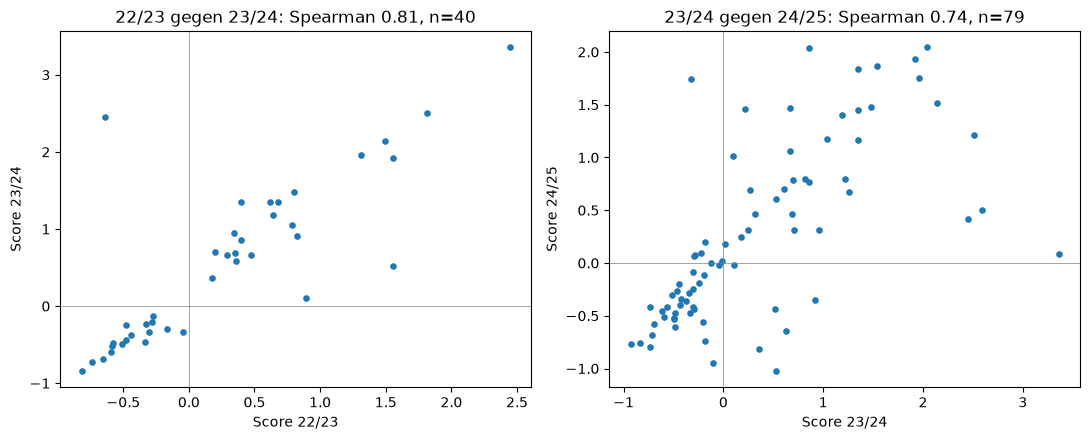

In [5]:
#Hält der Rang über die Winter? Wenn nicht, misst der Score eher den Winter als die Station.
breit = markiert.pivot_table(index="meter", columns="winter", values="score")
paare = [("22/23", "23/24"), ("23/24", "24/25")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (a, b) in zip(axes, paare):
    teil = breit[[a, b]].dropna()
    rho_ab = teil.corr(method="spearman").iloc[0, 1]
    ax.scatter(teil[a], teil[b], s=14)
    ax.axhline(0, color="grey", lw=0.5)
    ax.axvline(0, color="grey", lw=0.5)
    ax.set_xlabel(f"Score {a}")
    ax.set_ylabel(f"Score {b}")
    ax.set_title(f"{a} gegen {b}: Spearman {rho_ab:.2f}, n={len(teil)}")
plt.tight_layout()
plt.show()

**A2 · Zelle 3 · Hält der Score über die Winter?**

**Achsen**
- x = Score einer Station im früheren Winter, y = Score derselben Station im nächsten Winter (Berechnung siehe Zelle 2)
- 1 Punkt = 1 Station mit Score in beiden Wintern
- Linien bei 0 = typische Station --> rechts oben: in beiden Wintern schlechter als das Netz, links unten: in beiden besser
- Punkte nahe der Diagonale --> Station bleibt, wo sie war

**Ergebnis**
- Spearman 0,81 (22/23 → 23/24, 40 Stationen), 0,74 (23/24 → 24/25, 79 Stationen)
- gute Stationen bleiben gut, schlechte bleiben schlecht --> Score misst die Station, nicht den Winter
- erste Plausibilitätsprüfung: wäre rho nahe 0, würde der Score nur Zufall oder Wetter messen

**Warum 23/24 → 24/25 etwas niedriger**
- zwischen den beiden Wintern liegen fast alle Begehungen (Herbst 2024)
  --> echte Änderungen senken die Korrelation, z. B. 68956351: Score 3,36 --> 0,09, Rang 1 --> 40
  --> das ist gewollt: eine Reparatur soll im Score sichtbar werden


## A3 Chronisch auffällige Stationen

**A3 · Zelle 1 · Chronisch auffällige Stationen**

**Was gerechnet wird**
- A2 je Station über alle Winter zusammengefasst: Winter mit Score, wie oft auffällig, Median von Score und Rang
- chronisch = in mind. 2 Wintern auffällig, je_auffaellig = in mind. 1 Winter

**Ergebnis**
- 92 Stationen mit Score --> 17 mind. einmal auffällig, 8 chronisch
- chronisch: 68956351, 80912182, 72135442, 72167782, 72135453, 72167793, 72135480, 68956360
- 72135453 und 72135480 in allen 3 Wintern auffällig --> dauerhaft schlecht
- 68956351 auffällig 22/23 und 23/24, danach nicht mehr (Reparatur) --> bleibt trotzdem chronisch, 2 Winter reichen
- Stationen mit nur einem Winter mit Score (z. B. 81050517, 81062289, nur 24/25) können nicht chronisch sein

**Warum wichtig**
- chronische Stationen sieht der Tagesmonitor nicht, weil ihr Lernjahr schon schlecht war
  --> nur der Netzvergleich findet sie, 4 davon nie begangen (A4)


In [6]:
uebersicht = nv.stationsuebersicht(markiert)
uebersicht["je_auffaellig"] = uebersicht["n_auffaellig"] >= 1
print(f"{int(uebersicht['chronisch'].sum())} chronisch, "
      f"{int(uebersicht['je_auffaellig'].sum())} mindestens einmal auffällig, "
      f"von {len(uebersicht)} Stationen mit Score")
display(uebersicht[uebersicht["je_auffaellig"]].round(2))

8 chronisch, 17 mindestens einmal auffällig, von 92 Stationen mit Score


,meter,n_winter,n_auffaellig,score_median,rang_median,in_referenz,winter_auffaellig,chronisch,je_auffaellig
0,68956351,3,2,2.44,1.0,True,"22/23,23/24",True,True
1,80912182,2,2,2.04,3.5,True,"23/24,24/25",True,True
2,72135442,3,2,1.92,4.0,True,"22/23,24/25",True,True
3,72167782,3,2,1.81,3.0,True,"22/23,23/24",True,True
4,72135453,3,3,1.75,6.0,True,"22/23,23/24,24/25",True,True
5,72167793,2,2,1.71,6.5,True,"23/24,24/25",True,True
6,72167777,2,1,1.55,15.5,True,23/24,False,True
7,72135480,3,3,1.52,5.0,True,"22/23,23/24,24/25",True,True
9,80912173,2,1,1.45,11.5,True,24/25,False,True
10,68956360,3,2,1.35,12.0,True,"23/24,24/25",True,True


**A3 · Zelle 2 · Gegenprobe innerhalb der Leistungsklasse**

**Frage**
- ist auffällig nur "großes oder kleines Haus"? --> gleiche Rechnung, aber nur gegen Stationen ähnlicher Größe

**Wie**
- Klassen nach Anschlusswert: bis 5 kW, 5–10 kW, über 10 kW (Grenzen vom Team festgelegt)
- 23/24: 49 × 5–10 kW, 32 × über 10 kW, 1 × bis 5 kW, 4 × unbekannt
- Klasse braucht mind. 8 Vergleichsstationen, sonst und bei unbekanntem Anschlusswert Vergleich mit dem ganzen Netz (Spalte `netz`)

**Ergebnis**
- chronisch: Netz 8, Klasse 7, gemeinsam 7 --> Jaccard 0,88 (gemeinsame / alle verschiedenen = 7/8)
- nur 68956360 (8 kW) fällt raus: in der Klasse nur 24/25 auffällig statt 23/24 und 24/25
  --> Liste der chronischen Stationen hängt kaum von der Hausgröße ab
- Ivelinas Lauf (100 Zähler): Jaccard 1,0


In [7]:
#Sensitivität: Vergleich nur innerhalb der Leistungsklasse
klasse = nv.markiere(nv.netzbezug(tabelle, gruppe="leistungsklasse",
                                  referenz_ausschluss=tuple(bhkw) or nv.REFERENZ_AUSSCHLUSS), kz)
ue_kl = nv.stationsuebersicht(klasse)
a = set(uebersicht.loc[uebersicht["chronisch"], "meter"])
b = set(ue_kl.loc[ue_kl["chronisch"], "meter"])
jacc = len(a & b) / len(a | b) if a | b else np.nan
print(f"chronisch Netzbezug {len(a)}, Klassenbezug {len(b)}, gemeinsam {len(a & b)}, Jaccard {jacc:.2f}")
print("Bezug je Winter und Klasse:")
display(klasse.groupby(["winter", "bezug"]).size().unstack(fill_value=0))

chronisch Netzbezug 8, Klassenbezug 7, gemeinsam 7, Jaccard 0.88
Bezug je Winter und Klasse:


bezug,leistungsklasse,netz,zu_klein
winter,,,
22/23,38,3,0
23/24,81,5,0
24/25,80,4,0
25/26,0,0,4


## A4 Was haben die auffälligen Stationen gemeinsam?

**A4 · Was haben die auffälligen Stationen gemeinsam?**

**Was gerechnet wird**
- je Station Merkmale: Anschlusswert, Leistungsklasse, begangen ja/nein, Befunde aus NB 15 (Auto-Kodierung), Bauart
- Profil: Anteil (Ja/Nein) bzw. Median (Zahlen) in der Gruppe gegen den Rest
- Fisher = Test für Ja/Nein (2×2-Tafel), Mann-Whitney = Test für Zahlen (Reihenfolge der Werte)
- p-Wert = wie wahrscheinlich so ein Unterschied ohne echten Zusammenhang wäre, klein = eher kein Zufall
- Befunde nur für begangene Stationen --> n_gruppe = 4 bei den chronischen, nicht 8

**Ergebnis**
- 4 von 8 chronischen nie begangen: 68956360, 72135453, 72135480, 72167793 --> Kandidaten für die nächste Begehung
- 72167782: Begehung ohne Datum (hat_begehung True, n_begehungen 0)
- chronisch --> alle 4 begangenen mit Ventil-/Stellantrieb-Befund, Rest 9,6 % (p < 0,001)
- je einmal auffällig --> Ventil 44 % gegen 11 % (p = 0,029)
- Größe spielt keine Rolle: Anschlusswert 12 gegen 10 kW (p = 0,38)
- übrige Merkmale ohne Zusammenhang (p > 0,1)

**Vorsicht**
- nur 4 Stationen mit Befund, 12 Merkmale getestet --> kleiner p-Wert = Hinweis, kein Beweis
- Auto-Kodierung, mit Handbefunden (NB 29) dasselbe Bild (4 von 4)
- Begehungen nicht zufällig ausgewählt


In [8]:
labels = bc.labels_je_zaehler(bc.kodiere_begehungen())
kontext = nv.kontext_tabelle(uebersicht["meter"], anschlusswerte, bhkw, termine, labels,
                             begangen_ohne_datum=ohne_datum)
chron = kontext[kontext["meter"].isin(uebersicht.loc[uebersicht["chronisch"], "meter"])]
print("Chronische Stationen und Begehungen:")
display(chron[["meter", "hat_begehung", "n_begehungen"]])
print("Chronisch und nie begangen:",
      sorted(chron.loc[~chron["hat_begehung"], "meter"].tolist()))
for gruppe in ("chronisch", "je_auffaellig"):
    n = int(uebersicht[gruppe].sum())
    print(f"Profil für '{gruppe}' (n={n}):")
    if n < 3:
        print("  zu wenige Stationen für ein Profil")
        continue
    display(nv.profil(uebersicht, kontext, gruppe=gruppe).head(12).round(3))

/Users/seb/miniconda3/envs/projektseminar/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


Chronische Stationen und Begehungen:


,meter,hat_begehung,n_begehungen
12,68956351,True,1
18,68956360,False,0
33,72135442,True,1
35,72135453,False,0
39,72135480,False,0
45,72167782,True,0
49,72167793,False,0
72,80912182,True,1


Chronisch und nie begangen: [68956360, 72135453, 72135480, 72167793]
Profil für 'chronisch' (n=8):


,merkmal,auspraegung,test,n_gruppe,n_rest,wert_gruppe,wert_rest,p_wert
0,ventil_stellantrieb,,fisher,4,52,1.00,0.096,0.000
1,n_befunde,,mannwhitney,4,52,1.50,0.500,0.026
2,daemmung,,fisher,4,52,0.25,0.058,0.263
3,pumpe,,fisher,4,52,0.25,0.058,0.263
4,n_begehungen,,mannwhitney,8,84,0.00,1.000,0.276
5,schmutzfaenger,,fisher,4,52,0.25,0.096,0.373
6,anschlusswert_kw,,mannwhitney,8,77,12.00,10.000,0.381
7,regler_parameter,,fisher,4,52,0.25,0.115,0.423
8,leistungsklasse,über 10 kW,fisher,8,84,0.50,0.333,0.442
9,fussbodenheizung,,fisher,4,52,0.50,0.327,0.598


Profil für 'je_auffaellig' (n=17):


,merkmal,auspraegung,test,n_gruppe,n_rest,wert_gruppe,wert_rest,p_wert
0,ventil_stellantrieb,,fisher,9,47,0.444,0.106,0.029
1,pumpe,,fisher,9,47,0.222,0.043,0.117
2,daemmung,,fisher,9,47,0.222,0.043,0.117
3,n_begehungen,,mannwhitney,17,75,0.000,1.000,0.400
4,naturumlauf,,fisher,9,47,0.111,0.043,0.415
5,anlage_aus,,fisher,9,47,0.111,0.043,0.415
6,leistungsklasse,5-10 kW,fisher,17,75,0.471,0.587,0.426
7,anschlusswert_kw,,mannwhitney,15,70,10.000,10.000,0.450
8,n_befunde,,mannwhitney,9,47,1.000,1.000,0.461
9,fussbodenheizung,,fisher,9,47,0.444,0.319,0.470


## B1 Kernwinter vor gegen Kernwinter nach der Begehung

**B1 · Zelle 1 · Winterpaare und Kälte der Winter**

**Heizgradstunden je Kernwinter (DWD Kitzingen)**
- Summe über alle Stunden von (15 °C − Außentemperatur), wenn kälter als 15 °C --> größer = kälter
- 22/23 25.011, 23/24 22.619 (mildester), 24/25 27.366 (kältester, +21 % gegen 23/24), 25/26 27.174
  --> fast alle Paare sind 23/24 --> 24/25: Nachwinter deutlich kälter --> mehr Wärme, meist mehr Wasser

**Winterpaar je Begehung**
- Vorwinter = jüngster Kernwinter vor dem Termin mit genug Stunden, Nachwinter = frühester danach, je 7 Tage Abstand
- 58 Begehungen: ok 43, kein Nachwinter 6 (z. B. Termine 2025), keine Daten 5, zu wenig Punkte 2 (u. a. 72135443, Termin im Dez. 2024), kein Vorwinter 2
- Paare: 42 × 23/24 --> 24/25, 1 × 24/25 --> 25/26 (68956371)


In [9]:
try:
    temp = weather.load_outdoor_temperature("2022-11-01", "2026-03-01", allow_download=False)
    hgs = nv.heizgradstunden_je_winter(temp)
    display(hgs.round(0))
except Exception as fehler:
    print("Keine Außentemperatur verfügbar:", fehler)
    hgs = None

vergleich = km.wintervergleich(punkte, termine, anschlusswerte, markiert, hgs)
print(vergleich["status"].value_counts().to_string())
print("Termin im Kernwinter je Status:")
print(vergleich.groupby("status")["termin_im_winter"].sum().astype(int).to_string())
print("Ohne Nachwinter:")
print(vergleich.loc[vergleich["status"] == "kein_nachwinter", ["meter", "datum"]]
      .assign(datum=lambda d: d["datum"].dt.date).to_string(index=False))
ok = vergleich[vergleich["status"] == "ok"]
print("Winterpaare:")
display(ok.groupby(["winter_vor", "winter_nach"]).size().to_frame("Begehungen"))

,winter,heizgradstunden,n_stunden
0,22/23,25011.0,2160
1,23/24,22619.0,2184
2,24/25,27366.0,2160
3,25/26,27174.0,2160


status
ok                 43
kein_nachwinter     6
keine_daten         5
zu_wenig_punkte     2
kein_vorwinter      2
Termin im Kernwinter je Status:
status
kein_nachwinter    0
kein_vorwinter     0
keine_daten        0
ok                 0
zu_wenig_punkte    1
Ohne Nachwinter:
   meter      datum
68956367 2025-09-12
68956373 2025-03-12
72135441 2024-10-14
72135486 2025-09-13
72167783 2025-09-11
80912165 2024-09-09
Winterpaare:


,,Begehungen
winter_vor,winter_nach,
23/24,24/25,42
24/25,25/26,1


**B1 · Zelle 2 · Vorher/Nachher je Begehung**

**Was verglichen wird**
- nicht nur Durchfluss: alle Kennzahlen aus A1 werden für Vor- und Nachwinter neu gerechnet
  --> Differenzen nachher − vorher: d_steigung, d_spreizung_ref_k, d_residuum_sd, d_rl_ueber_50_anteil, d_flow_spez_lh_kw, d_flow_median_lh
- Tabelle zeigt davon Durchfluss (Hauptgröße), Steigung, Spreizung, Kreuzresiduum, Rang; Rest wird in B2 gegen die Kontrollgruppe getestet

**Spalten**
- flow_median vor/nach = Median Volumenstrom im Kernwinter, Verhältnis = nachher / vorher (0,18 = nur noch 18 %)
- flow_bei_pref vor/nach = Wasser, das die Kennlinie bei derselben Leistung vorhersagt --> rechnet den kälteren Winter heraus
- d_steigung > 0 = Wasser folgt nachher besser dem Bedarf, d_spreizung_ref_k > 0 = kühlt nachher stärker ab
- residuum_kreuz = Stunden des Nachwinters gegen die Kennlinie des Vorwinters, negativ = weniger Wasser bei gleicher Leistung = besser
- rang vor/nach = Gesamtsicht über alle 5 Kennzahlen aus A2, bezogen auf den ganzen Winter
- weitere_begehung = zweiter Termin (68956342 steht deshalb zweimal drin)

**Ergebnis**
- wenige klare Verbesserungen:
  - 68956351: Wasser 567 --> 103 l/h, Steigung +1,38, Spreizung +21,6 K, Kreuzresiduum −1,53, Rang 1 --> 40
  - 68956372: Wasser 329 --> 131 l/h, Spreizung +13,4 K, Rang 4 --> 32
- die meisten unverändert (Verhältnis 0,9–1,1)
- einige nachher deutlich mehr Wasser: 72135442 193 --> 407 l/h (Rang 8 --> 3), 80912173 171 --> 323 l/h (Rang 21 --> 2)
  --> bei 80912173 auch bei gleicher Leistung mehr (129 --> 298) --> echte Änderung, nicht nur der kältere Winter
- ob das eine Wirkung der Begehungen ist, zeigt erst B2 mit der Kontrollgruppe


In [10]:
spalten = ["meter", "datum", "winter_vor", "winter_nach",
           "flow_median_lh_vor", "flow_median_lh_nach", "d_flow_median_lh",
           "flow_verhaeltnis", "flow_bei_pref_vor", "flow_bei_pref_nach",
           "d_steigung", "d_spreizung_ref_k", "residuum_kreuz",
           "rang_vor", "rang_nach", "weitere_begehung"]
tabelle_b1 = ok[spalten].assign(datum=ok["datum"].dt.date)
display(tabelle_b1.sort_values("d_flow_median_lh").round(2))
print(f"Gegenprobe {BEISPIEL} (Ventilreparatur Sep. 2024):")
display(tabelle_b1[tabelle_b1["meter"] == BEISPIEL].round(3).T)

,meter,datum,winter_vor,winter_nach,flow_median_lh_vor,flow_median_lh_nach,d_flow_median_lh,flow_verhaeltnis,flow_bei_pref_vor,flow_bei_pref_nach,d_steigung,d_spreizung_ref_k,residuum_kreuz,rang_vor,rang_nach,weitere_begehung
6,68956351,2024-09-09,23/24,24/25,567.0,103.0,-464.0,0.18,518.07,58.68,1.38,21.60,-1.53,1.0,40.0,False
16,68956372,2024-10-14,23/24,24/25,329.0,131.0,-198.0,0.40,328.80,99.45,0.66,13.43,-0.91,4.0,32.0,False
5,68956348,2024-09-09,23/24,24/25,809.0,703.0,-106.0,0.87,803.64,784.11,0.05,0.19,-0.05,15.0,21.0,False
52,80912193,2024-11-05,23/24,24/25,206.0,169.0,-37.0,0.82,210.63,177.27,-0.09,5.62,-0.15,50.0,78.0,False
30,80912154,2024-09-23,23/24,24/25,217.0,189.0,-28.0,0.87,222.60,151.63,0.07,9.86,-0.42,35.0,66.0,False
37,80912164,2024-08-26,23/24,24/25,95.0,68.0,-27.0,0.72,98.00,100.69,-0.15,-3.68,0.04,58.0,42.0,False
32,80912159,2024-09-10,23/24,24/25,162.0,141.0,-21.0,0.87,155.73,161.02,-0.09,-0.83,0.03,74.0,72.0,False
10,68956356,2024-09-19,23/24,24/25,233.0,216.0,-17.0,0.93,181.26,198.10,-0.73,-1.64,0.19,10.0,9.0,False
46,80912180,2024-09-20,23/24,24/25,117.0,111.0,-6.0,0.95,122.95,119.46,-0.17,0.96,-0.08,78.0,64.0,False
25,72135486,2024-09-11,23/24,24/25,35.0,33.0,-2.0,0.94,36.16,34.90,0.06,0.99,-0.09,71.0,75.0,False


Gegenprobe 68956351 (Ventilreparatur Sep. 2024):


,6
meter,68956351
datum,2024-09-09
winter_vor,23/24
winter_nach,24/25
flow_median_lh_vor,567.0
flow_median_lh_nach,103.0
d_flow_median_lh,-464.0
flow_verhaeltnis,0.182
flow_bei_pref_vor,518.074
flow_bei_pref_nach,58.682


## B2 Begehungsfälle gegen Stationen ohne Begehung

**B2 · Zelle 1 · Wirkung der Begehungen auf Gruppenebene**

**Gruppen**
- Begehung: Paar 23/24 --> 24/25, jede Station einmal --> 42 Begehungen an 41 Stationen (68956342 zwei Termine)
- Kontrolle: 29 Stationen ohne Begehung mit beiden Wintern, dieselbe Differenz 24/25 − 23/24
  --> ohne 5 Stationen mit Begehung ohne Datum (65273846, 68956347, 72135481, 72167782, 80912202)
- Test: Median der Differenzen je Gruppe, Mann-Whitney (sind die Werte einer Gruppe tendenziell größer?)

**Ergebnis**
- Wasser nachher/vorher: Begehung 1,075 (+7,5 %), Kontrolle 1,154 (+15 %) --> beide mehr Wasser, weil 24/25 kälter
- Spreizung +0,43 K gegen −0,41 K, RL > 50 °C −2,1 %-Punkte gegen ±0 --> Begangene leicht besser
- kein Unterschied signifikant (p 0,30–0,92) --> keine Wirkung der Begehungen auf Gruppenebene nachweisbar
- Gründe: wenige starke Erfolge gehen in vielen unveränderten Fällen unter, meist nur Einstellungen geändert (verändern die Kennlinie kaum), kleine Gruppen
- Boxplots: Wasser-Verhältnis, Steigung, Spreizung --> Boxen fast deckungsgleich


Kontrollgruppe 29 Stationen, ohne Datum ausgeschlossen: [65273846, 68956347, 72135481, 72167782, 80912202]


,spalte,n_begehung,median_begehung,n_kontrolle,median_kontrolle,p_mw
0,d_steigung,41,0.007,29,-0.001,0.867
1,d_spreizung_ref_k,41,0.429,29,-0.412,0.600
2,d_residuum_sd,41,-0.002,29,0.005,0.482
3,d_rl_ueber_50_anteil,41,-0.021,29,0.000,0.300
4,d_flow_median_lh,41,10.000,29,8.000,0.663
5,flow_verhaeltnis,41,1.075,29,1.154,0.915
6,d_flow_spez_lh_kw,40,0.893,28,1.075,0.751
7,residuum_kreuz,41,-0.046,29,0.013,0.535


42 Begehungen an 41 Stationen mit dem Paar 23/24 gegen 24/25


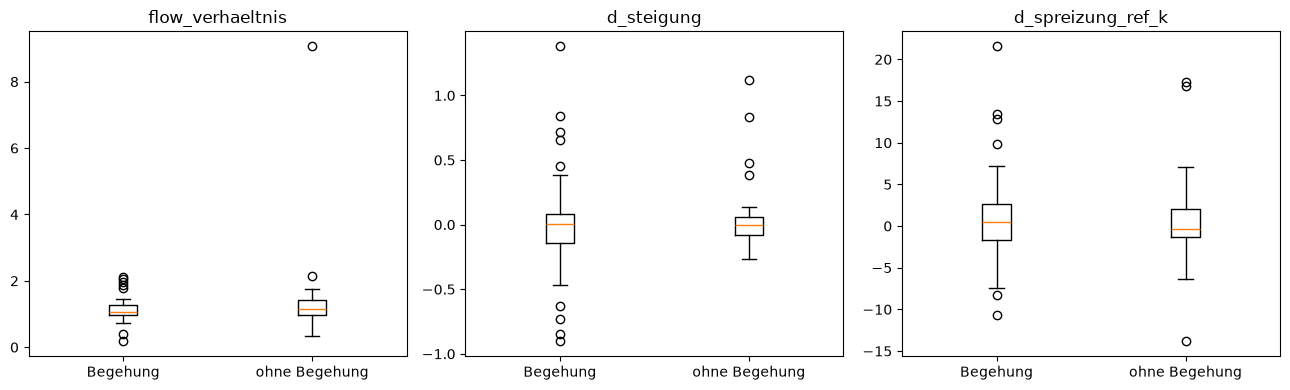

In [11]:
kontrolle = km.winterdifferenz_kontrolle(tabelle, termine, punkte=punkte, ausschluss=ohne_datum)
print(f"Kontrollgruppe {len(kontrolle)} Stationen, "
      f"ohne Datum ausgeschlossen: {sorted(ohne_datum & set(tabelle['meter'].astype(int)))}")
gv = km.gruppenvergleich(vergleich, kontrolle)
display(gv.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
paar_alle = ok[(ok["winter_vor"] == "23/24") & (ok["winter_nach"] == "24/25")]
paar = (paar_alle.sort_values(["meter", "datum"])
        .drop_duplicates(["meter", "winter_vor", "winter_nach"]))
print(f"{len(paar_alle)} Begehungen an {len(paar)} Stationen mit dem Paar 23/24 gegen 24/25")
for ax, s in zip(axes, ("flow_verhaeltnis", "d_steigung", "d_spreizung_ref_k")):
    ax.boxplot([paar[s].dropna(), kontrolle[s].dropna()])
    ax.set_xticks([1, 2], ["Begehung", "ohne Begehung"])
    ax.set_title(s)
plt.tight_layout()
plt.show()

**B2 · Zelle 2 · Wechsel der Auffälligkeit**

- vorher auffällig --> nachher unauffällig: 2 (68956351, 68956372) = die klaren Erfolge aus B1
- vorher auffällig --> bleibt auffällig: 1 (80912182)
- vorher unauffällig --> nachher auffällig: 3 (72135442, 80912173, 68956359)
  --> alle drei nachher deutlich mehr Wasser (193 --> 407, 171 --> 323, 123 --> 243 l/h)
  --> Einstellung verschlechtert oder andere Ursache --> Begehungsnotizen prüfen
- 35 von 41 bleiben unauffällig


In [12]:
#Wechsel der Netzauffälligkeit über die Begehung, jede Station einmal
wechsel = paar.dropna(subset=["auffaellig_vor", "auffaellig_nach"])
display(pd.crosstab(wechsel["auffaellig_vor"].map({True: "auffällig vorher", False: "unauffällig vorher"}),
                    wechsel["auffaellig_nach"].map({True: "auffällig nachher", False: "unauffällig nachher"})))

auffaellig_nach,auffällig nachher,unauffällig nachher
auffaellig_vor,,
auffällig vorher,1,2
unauffällig vorher,3,35


## C Stationsblatt je Station

- `src/stationsblatt.py` zeigt je Station Steigung und Spreizung aus dem gleitenden Fenster des Monitors vor dem Netzband (10. bis 90. Perzentil aller Stationen am selben Tag, ohne BHKW), darunter Kennlinie je Kernwinter und Netz-z-Werte.
- Export aller Bilder mit `python -m src.stationsblatt` (einige Minuten), hier nur das Beispiel.

93 Statuszeilen, 92 mit Netzwert, 271 s


grund
               92
keine_daten     1
Name: count, dtype: int64

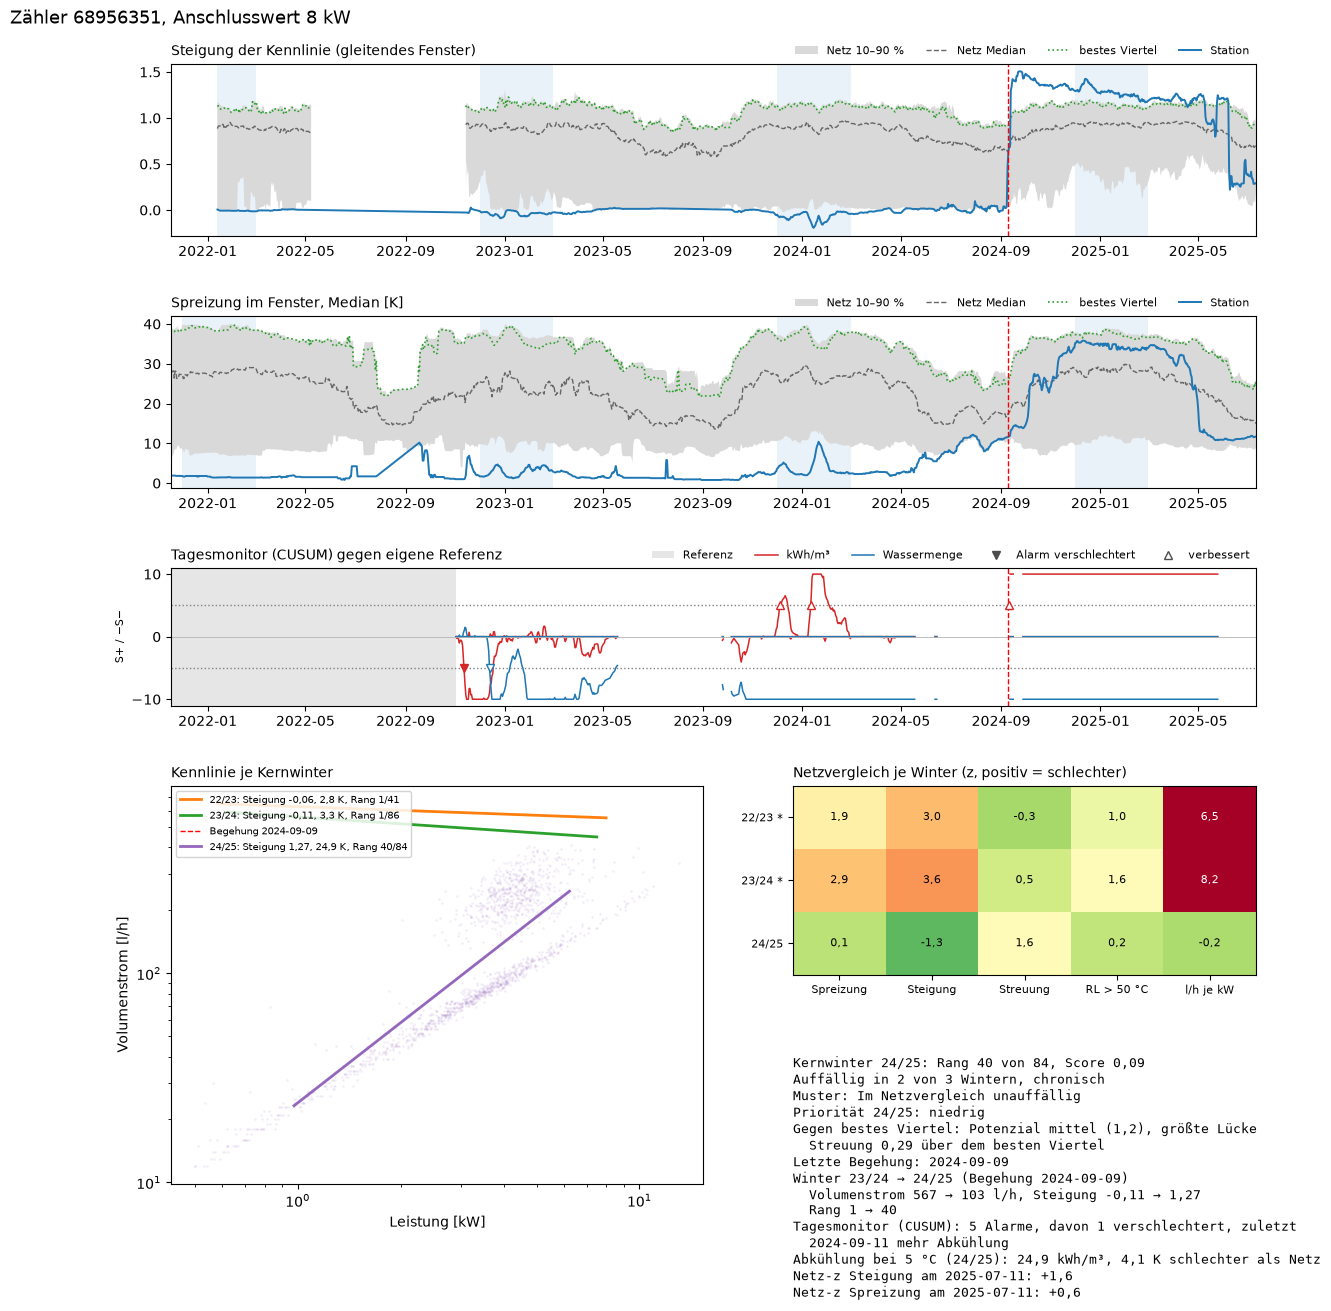

In [13]:
from src import stationsblatt as bl

t0 = time.time()
blatt = bl.rechne(serien, termine, anschlusswerte, bhkw, ohne_datum)
status = bl.statustabelle(blatt)
print(f"{len(status)} Statuszeilen, {status['score'].notna().sum()} mit Netzwert, "
      f"{time.time() - t0:.0f} s")
display(status["grund"].value_counts())
fig = bl.zeichne_stationsblatt(BEISPIEL, blatt, status[status["meter"] == BEISPIEL].iloc[0])
plt.show()

**C · Zelle 1 · Ganzes Modell rechnen und Stationsblatt**

**Was gerechnet wird**
- bl.rechne = dieselbe Funktion wie im Endprodukt (python -m src.aktualisieren)
  --> Netzvergleich (A), Wintervergleich (B), Fenstermonitor NB 14, Tagesmonitor, Priorität in einem Durchlauf (~4–5 min)
- statustabelle: 93 Zeilen, 92 mit Netzwert, 1 ohne Daten

**Stationsblatt 68956351 lesen**
1. Steigung im gleitenden Fenster: Station (blau) vor dem Netzband (grau = 10–90 % aller Stationen am selben Tag, gestrichelt Median, grün bestes Viertel), hellblau = Kernwinter, rot = Begehung
   --> bis 09/2024 Steigung ≈ 0 weit unter dem Band, nach der Reparatur ≈ 1,4
2. Spreizung im Fenster: vorher 1–10 K unter dem Band, nachher 25–35 K im besten Viertel
   --> Sommer 2025 sinken beide wieder (Sommer = fast nur Warmwasser, Band sinkt mit) --> erst der nächste Winter zeigt, ob es wieder schlechter wird
3. Tagesmonitor: grau = Lernjahr, rot = Konto Abkühlung, blau = Konto Wassermenge, ▼ = Alarm verschlechtert, △ = verbessert (2 Tage nach der Reparatur)
4. Kennlinie je Kernwinter: 22/23 und 23/24 flach (−0,06 / −0,11) bei viel Wasser, 24/25 steil (1,27)
5. Heatmap: z-Werte je Winter und Kennzahl, * = auffällig, rot = schlecht
6. Textblock = Statuszeile: Rang, chronisch, Priorität, Potenzial, Wintervergleich, Alarme, Abkühlung bei 5 °C


In [14]:
spalten = ["meter", "winter", "rang", "n_stationen", "auffaellig", "chronisch",
           "wv_status", "wv_flow_vor_lh", "wv_flow_nach_lh", "tm_alarme", "hinweis"]
display(status.sort_values("score", ascending=False)[spalten].head(10).round(2))

,meter,winter,rang,n_stationen,auffaellig,chronisch,wv_status,wv_flow_vor_lh,wv_flow_nach_lh,tm_alarme,hinweis
73,80912182,24/25,1.0,84.0,True,True,ok,510.5,545.0,3,"Referenzspreizung klein, Steigung niedrig, oft..."
66,80912173,24/25,2.0,84.0,True,False,ok,171.0,323.0,3,"Referenzspreizung klein, Steigung niedrig, oft..."
34,72135442,24/25,3.0,84.0,True,True,ok,193.0,407.0,8,"Kennlinie unruhig, hoher Volumenstrom je kW"
50,72167793,24/25,4.0,84.0,True,True,,NaN,NaN,2,"Referenzspreizung klein, Steigung niedrig, oft..."
9,68956344,24/25,5.0,84.0,False,False,ok,186.0,259.0,4,Kennlinie unruhig
36,72135453,24/25,6.0,84.0,True,True,,NaN,NaN,12,"Referenzspreizung klein, oft Rücklauf über 50 ..."
89,80956410,24/25,7.0,84.0,True,False,,NaN,NaN,2,"Referenzspreizung klein, Kennlinie unruhig, ho..."
40,72135480,24/25,8.0,84.0,True,True,,NaN,NaN,10,"Referenzspreizung klein, Steigung niedrig, oft..."
17,68956356,24/25,9.0,84.0,False,False,ok,233.0,216.0,6,Steigung niedrig
27,68956373,24/25,10.0,84.0,True,False,kein_nachwinter,NaN,NaN,11,"Referenzspreizung klein, Kennlinie unruhig, ho..."


**C · Zelle 2 · Top 10 als Statuszeilen**

**Sortierung**
- nach Score im jüngsten Winter (24/25), nicht nach Priorität
- Score = Mittel der 5 z-Werte aus A2 (0 = typische Station, positiv = schlechter), nur Netzvergleich
  --> Beispiel 68956351 in 23/24: (2,92 + 3,64 + 0,47 + 1,58 + 8,19) / 5 = 3,36
- Priorität kombiniert Netz auffällig + Verschlechterungsalarm aus dem Tagesmonitor
  --> hoher Score ≠ hohe Priorität, hoher Score ≠ auffällig (z. B. 68956344 Rang 5, nur 1 Kennzahl schlecht)

**Spalten**
- wv_* = Wintervergleich aus B1 (leer = nie begangen, kein_nachwinter = Begehung zu spät für einen Winter danach)
- tm_alarme = Zahl der Tagesmonitor-Alarme
- hinweis = Muster der schlechten Kennzahlen als Text

**Ergebnis**
- 4 der Top 10 nie begangen: 72167793, 72135453, 80956410, 72135480 (3 davon chronisch) --> Kandidaten für die nächste Begehung
- 80912173 und 72135442 nach ihrer Begehung schlechter geworden (B2)


## Zusammenfassung & Bewertung

## Zusammenfassung & Bewertung

*Neu geschrieben nach der Durchsicht von A1–C, Zahlen aus dem Lauf vom 24.10.2026 (NB 00, 93 HAST)*

**Worum es geht**
- Teil A: welche Stationen laufen im Kernwinter schlechter als die anderen? --> geht in die Priorität ein
- Teil B: hat die Begehung etwas gebracht? --> Erfolgskontrolle, nur Info in der Statuszeile
- Teil C: beides plus Tagesmonitor als Stationsblatt und Statuszeile je Station

**Ergebnis Teil A (Netzvergleich)**
- 377.385 Betriebsstunden --> 215 Zeilen (Station × Winter) × 5 Kennzahlen, Stationen je Winter: 22/23 41, 23/24 86, 24/25 84
- auffällig je Winter: 6 / 9 / 12, mind. einmal auffällig 17, chronisch 8:
  68956351, 80912182, 72135442, 72167782, 72135453, 72167793, 72135480, 68956360
- 4 chronische nie begangen: 68956360, 72135453, 72135480, 72167793 --> Kandidaten für die nächste Begehung
- zwei Muster: Ventilmuster (Spreizung, Steigung, RL, Wasser schlecht, Streuung normal) und unruhig (vor allem Streuung hoch)
- chronisch --> alle 4 begangenen mit Ventil-/Stellantrieb-Befund (Rest 9,6 %, p < 0,001), je einmal auffällig 44 % gegen 11 % (p = 0,029)
  --> mit den Handbefunden (NB 29) dasselbe Bild

**Ergebnis Teil B (Wintervergleich)**
- 58 Begehungen, 43 auswertbar, fast alle 23/24 --> 24/25; 24/25 war 21 % kälter (Heizgradstunden)
- einzelne klare Erfolge: 68956351 (567 --> 103 l/h, Rang 1 --> 40), 68956372 (329 --> 131 l/h, Rang 4 --> 32)
- 3 Stationen nach der Begehung neu auffällig, alle mit deutlich mehr Wasser: 72135442, 80912173, 68956359
- gegen 29 Kontrollstationen: kein Unterschied signifikant (p 0,30–0,92) --> Wirkung auf Gruppenebene nicht nachweisbar

**Belastbar**
- Rangliste stabil über die Winter (Spearman 0,81 und 0,74) --> Score misst die Station, nicht den Winter
- Liste der chronischen Stationen hängt kaum von der Hausgröße ab (Leistungsklasse: 7 von 8 gleich, nur 68956360 fällt raus)
- bekannter Fall 68956351: Fehler (Rang 1) und Reparatur (Rang 40, Steigung −0,11 --> 1,27) richtig erkannt
- Zusammenhang chronisch/auffällig <--> Ventilbefund, mit Auto- und Handbefunden

**Schwach**
- sehr kleine Fallzahlen: 4 chronische mit Befund, 41 gegen 29 Stationen in B, viele Tests nebeneinander --> p-Werte = Hinweise
- Begehungen nicht zufällig ausgewählt, fast alle im Herbst 2024
- Streuung nur bedingt aussagekräftig: Stundenwerte sind Momentaufnahmen --> Takten erscheint als Rauschen, Regelhysterese nicht nachweisbar
- nur Kernwinter: Sommer-Nachtdurchfluss (stärkstes Ventilmerkmal bei Dominik) fehlt, 21/22 fällt ganz raus, 22/23 nur 41 Stationen, 25/26 ohne Netzwert
- Wirkung meist kleiner Einstellungsänderungen in den Winterkennzahlen kaum sichtbar

**Gesetzt, nicht aus den Daten hergeleitet**
- schlechtestes Zehntel, mind. 2 Kennzahlen, mind. 2 Winter, mind. 300 h, mind. 20 Stationen, Leistungsklassen 5/10 kW
- ±7 Tage um Begehungen (symmetrisch aus NB 08/12, Tage davor nur Vorsicht; betrifft heute nur 72135443 und 68956339)

**Offen**
- die 4 chronischen, nie begangenen Stationen begehen
- bei 72135442, 80912173, 68956359 Begehungsnotizen und Einstellungen prüfen (nachher mehr Wasser)
- Schwellen im Team festlegen, Puffer ggf. nur nach der Begehung
- Sommer-Kennzahl (Nachtdurchfluss) ergänzen
- für Regelhysterese: bei Frank Minutenwerte oder Reglerdaten mit Stellsignal anfragen
